&nbsp;

# Visualise up5p transcript - CRE Pairs with Genome Tracks

&nbsp;

## Objective

- 注目した transcript - CRE pair を、`pyGenomeTracks` で可視化し、Hi-C データなどと比較する

&nbsp;

## required process

[pyGenomeTracks](https://pygenometracks.readthedocs.io/en/latest/) は **tracks.ini + 描画領域 (`chr:start-end`)** で図を作る。全ゲノム一括ではなく、transcript–CRE pair ごとに窓を切る。

公式の流れは `make_tracks_file` で ini の雛形を作り、`pyGenomeTracks --tracks tracks.ini --region chrN:start-end -o fig.png` で描画する。[Usage](https://pygenometracks.readthedocs.io/en/latest/content/usage.html)

&nbsp;

### いまあるもの / 足りないもの

- 導入済み: `pyGenomeTracks` 3.9、`make_tracks_file`、`cooler` 0.9.3
- **未導入（必須）**: `bedtools`（3.5 以降の依存。[FAQ](https://pygenometracks.readthedocs.io/en/latest/content/faq.html)）
- **未導入（Hi-C 用）**: `hic2cool` または HiCExplorer `hicConvertFormat`
- アノテーション:
  - GENCODE v49 GTF: `Data/Database/GENCODE_v49/gencode.v49.annotation.gtf`（約 3.1 GB。パッチ込みは使わない）
  - transcript BED / TSS: `gencode.v49.annotation_transcript_id.bed`, `gencode.v49.transcript_tss_1bp.bed`
- fanta.bio:
  - 全 CRE: `Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed`（11 列、9 列目が RGB）
  - up5p サブセット: `out/fantabio/BEDfile/up5p/*.bed`（3 列なのでラベルなし）
- Hi-C / HiChIP: Juicer `.hic` と h1d dump（`*.KR.chrN.5000.matrix.gz`）、IS / ISC / IF の **染色体ごとの bedGraph**
- cool / h5 は **まだ無い**

&nbsp;

### 1. ソフトウェア

1. `bedtools` を入れる（pybedtools だけでは足りない）
2. `.hic` → `.cool` 用に `hic2cool`（または `hicConvertFormat`）を入れる

&nbsp;

### 2. アノテーションを軽くする（GTF / BED）

pyGenomeTracks の [gtf](https://pygenometracks.readthedocs.io/en/latest/content/tracks/gtf.html) は初回に gffutils で index する。v49 全長 GTF を渡すと重いので、**描画窓に重なる transcript だけ** GTF または BED12 に切り出す。

- 注目 transcript + 近傍遺伝子: GTF subset、または既存 transcript BED を `chr` 付き primary 染色体だけに絞る
- TSS を縦線にするなら `gencode.v49.transcript_tss_1bp.bed` を [vlines](https://pygenometracks.readthedocs.io/en/latest/content/all_tracks.html) 用に BED 化する
- fanta.bio 全 CRE も窓で subset する。RGB を使うなら 9 列以上を残し、ini で `color = bed_rgb`。[bed](https://pygenometracks.readthedocs.io/en/latest/content/tracks/bed.html)
- up5p 3 列 BED は区間表示だけならそのままでよい。名前を出すなら 4 列目に `cre_id` を足す

&nbsp;

### 3. Hi-C を cool にする

[hic_matrix](https://pygenometracks.readthedocs.io/en/latest/content/tracks/hic_matrix.html) / [hic_matrix_square](https://pygenometracks.readthedocs.io/en/latest/content/tracks/hic_matrix_square.html) が読めるのは **cool と HiCExplorer h5 だけ**。`.hic` も h1d dump も直接は不可。

優先順位:

1. 既存 `.hic` を 5000 bp で `.cool` へ（HS / Ctrl の Hi-C と CTCF HiChIP）
2. dump `matrix.gz` からの変換は最終手段（独自 dense 形式）

三角ヒートマップは `file_type = hic_matrix`（`depth` で描く距離）、正方は `hic_matrix_square`。接触の上に pair を重ねるなら links を `loops` / `triangles` にする。

&nbsp;

### 4. 1D 指標（IS / ISC / IF）は bedGraph のまま

[bedgraph](https://pygenometracks.readthedocs.io/en/latest/content/tracks/bedgraph.html) で染色体ファイルをそのまま使える（`--region` がその染色体なら concat は不要）。

- 例: `out/h1d/GSE105028_hic/score_single/HS_IS/HiC_HS_merged.KR.chr21.5000.matrix.IS.bedGraph`
- IS はスコア空欄の行がある（chr21 で約 1/4）。ini で `nans_to_zeros = true`
- HiChIP IF は KR が空の染色体をスキップ済み（HS: chr7/16/X、Ctrl: chr1/5/7/11/12/17/19/X）。その染色体の pair では IF トラックを外す

&nbsp;

### 5. transcript–CRE pair を links にする

[links](https://pygenometracks.readthedocs.io/en/latest/content/tracks/links.html) はタブ区切り:

`chr1  start1  end1  chr2  start2  end2  [score]`

[04_up5p_join_re2g.ipynb](./04_up5p_join_re2g.ipynb) の enhancer CRE と target CRE 座標から `.links`（または `.arcs`）を書く。スコアは rE2G の予測値など任意。

`--region` は **同じ染色体内の 2 区間を覆う窓 + padding**。染色体をまたぐ pair は標準の 1 枚図には向かない。

&nbsp;

### 6. tracks.ini を組んで 1 locus で試す

推奨トラック順（上から）:

1. Hi-C HS（`hic_matrix`）
2. Hi-C Ctrl（または ISC bedGraph）
3. IS HS / IS Ctrl
4. （任意）CTCF HiChIP IF
5. fanta.bio CRE BED
6. GENCODE subset GTF/BED
7. transcript–CRE links（`arcs`）
8. `x_axis`

```bash
make_tracks_file -f \
  path/to/HS.5000.cool \
  path/to/chrN.IS.bedGraph \
  path/to/window.cre.bed \
  path/to/window.gtf \
  path/to/pair.links \
  -o tracks.ini

pyGenomeTracks --tracks tracks.ini \
  --region chrN:start-end \
  --outFileName pair.png
```

ini を編集して `file_type`、`transform = log1p`（Hi-C）、`nans_to_zeros`、`color = bed_rgb` を整える。まず chr21 など 1 pair で確認する。


In [29]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import subprocess
import plotly.express as px
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import Image, display

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

&nbsp;

&nbsp;

&nbsp;

## Test 1: GENCODE release 49 GTF file & fanta.bio BED file

- 領域: [UCSC hg38 chr6:31,808,602-31,836,141](https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr6%3A31808602-31836141)（HSPA1A / HSPA1L / HSPA1B 座）
- 入力は全ゲノムのまま渡さない。GTF は約 3.3 GB あるので、先に窓へ切り出す
- fanta.bio CRE は 11 列（10 列目が `cp5@HSPA1L` など、9 列目が RGB）。pyGenomeTracks は BED9 までしか RGB を読まないので、9 列に直す
- コンタクトマップは使わない。トラックは CRE → GENCODE の 2 本

必要な操作:

1. `region.bed` を書く（`chr6  31808602  31836141`）
2. `bedtools intersect -wa` で GTF と CRE を切る
3. CRE を BED9 にする（name = 10 列目、itemRgb = 9 列目）
4. `tracks.ini` を書く（`color = bed_rgb`、GTF は `prefered_name = gene_name`）
5. `pyGenomeTracks --tracks tracks.ini --region chr6:31808602-31836141 -o fig.png`


In [30]:
# UCSC window: chr6:31,808,602-31,836,141 (HSPA1 locus)
REGION_CHROM = "chr6"
REGION_START = 31_800_000
REGION_END = 31_840_000

# REGION_START = 31_808_602
# REGION_END = 31_836_141

repo_root = pathlib.Path("../..").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/integrated_analysis/genometrack_test"
    / f"{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

region_bed = out_dir / "region.bed"
gtf_window = out_dir / "gencode.v49.gtf"
cre_window = out_dir / "fantabio.cre.bed"
cre_bed9 = out_dir / "fantabio.cre.bed9.bed"
tracks_ini = out_dir / "tracks.ini"
figure_png = out_dir / "gencode_fantabio.png"

region_bed.write_text(f"{REGION_CHROM}\t{REGION_START}\t{REGION_END}\n")
print(out_dir)

/workspaces/HS_human_ncRNA/out/integrated_analysis/genometrack_test/chr6_31800000_31840000


In [31]:
# Subset GTF and CRE to the plot window (keep GTF header comments).
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
gtf_hits = subprocess.run(
    ["bedtools", "intersect", "-a", str(gtf_full), "-b", str(region_bed), "-wa"],
    check=True,
    capture_output=True,
    text=True,
)
gtf_window.write_text(gtf_header.stdout + gtf_hits.stdout)

subprocess.run(
    ["bedtools", "intersect", "-a", str(cre_full), "-b", str(region_bed), "-wa"],
    check=True,
    stdout=cre_window.open("w"),
)

# Rewrite fanta.bio 11-column BED as BED9 so itemRgb is used.
with cre_window.open() as handle_in, cre_bed9.open("w") as handle_out:
    for line in handle_in:
        cols = line.rstrip("\n").split("\t")
        name = cols[9] if len(cols) > 9 and cols[9] else cols[3]
        handle_out.write(
            "\t".join(
                [cols[0], cols[1], cols[2], name, cols[4], cols[5], cols[6], cols[7], cols[8]]
            )
            + "\n"
        )

print(f"GTF features: {sum(1 for line in gtf_window.read_text().splitlines() if not line.startswith('#'))}")
print(f"CRE intervals: {sum(1 for _ in cre_bed9.open())}")


GTF features: 329
CRE intervals: 47


INFO:pygenometracks.tracksClass:initialize 1. [x-axis]
INFO:pygenometracks.tracksClass:initialize 2. [spacer]
INFO:pygenometracks.tracksClass:initialize 3. [fanta CRE]
100%|██████████| 47/47 [00:00<00:00, 124060.60it/s]
INFO:pygenometracks.tracksClass:initialize 4. [spacer]
INFO:pygenometracks.tracksClass:initialize 5. [GENCODE v49]
100%|██████████| 59/59 [00:00<00:00, 14149.69it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.03391218185424805
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 9.308510638297873. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [x-axis]
INFO:pygenometracks.tracksClass:plotting 2. [spacer]
INFO:pygenometracks.tracksClass:plotting 3. [fanta CRE]
DEBUG:pygenometracks.tracks.GenomeTrack:ylim 21.78,-0.08
DEBUG:pygenometracks.tracks.GenomeTrack:ylim (np.float64(21.78), np.float64(-0.08))
INFO:pygenometracks.tracksClass:plotting 4. [spacer]
INFO:pygenometracks.tracksClass:plotting 5. [GE

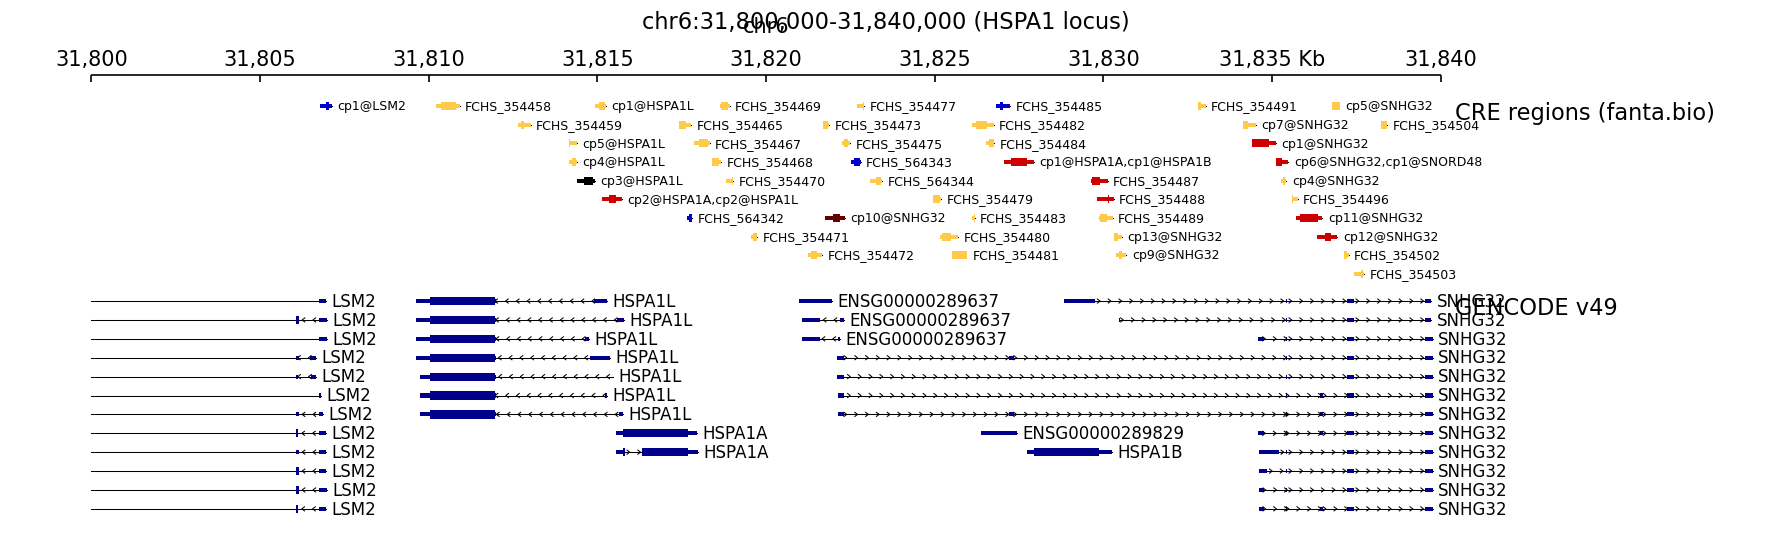

In [32]:
tracks_ini.write_text(
    """\
[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.2

[fanta CRE]
file = fantabio.cre.bed9.bed
title = CRE regions (fanta.bio)
file_type = bed
height = 3
color = bed_rgb
border_color = none
labels = true
fontsize = 6
style = UCSC
display = stacked
max_labels = 80

[spacer]
height = 0.3

[GENCODE v49]
file = gencode.v49.gtf
title = GENCODE v49
file_type = gtf
height = 4
color = darkblue
prefered_name = gene_name
merge_transcripts = false
labels = true
fontsize = 8
style = UCSC
display = stacked
gene_rows = 12
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.12",
        "--outFileName",
        str(figure_png),
        "--title",
        f"{REGION_CHROM}:{REGION_START:,}-{REGION_END:,} (HSPA1 locus)",
    ],
    check=True,
    cwd=out_dir,
)

from IPython.display import Image, display

display(Image(filename=str(figure_png)))

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Test 2: ENCODE-rE2G で予測された enhancer–promoter

- 入力: [FCHS_354475_e2g_join_filter_unique_count_join_stringent.ndjson](../../out/integrated_analysis/up5p_encode_rE2G_result/FCHS_354475_e2g_join_filter_unique_count_join_stringent.ndjson)（[04_up5p_join_re2g.ipynb](./04_up5p_join_re2g.ipynb) の stringent 結果）
- トラックに残すのは ndjson に出る **シスエレメントと transcript だけ**
  - CRE: `FCHS_354475`（ELA enhancer）→ `FCHS_354464` / `FCHS_354486`（PLA promoter）
  - transcript: enhancer 側 3 本、target 側 8 本
- 相互作用は CRE–CRE の 2 本を [links / arcs](https://pygenometracks.readthedocs.io/en/latest/content/tracks/links.html) にする（同じ CRE 対が transcript 行で重複するため `Score_mean` で 1 本にまとめる）
- Test 1 と同じ窓 `chr6:31808602-31836141`。先に Test 1 を実行して窓付き GTF / CRE を作っておく

In [33]:
# Test 2 uses the same UCSC window as Test 1.
from IPython.display import display

ndjson_path = (
    repo_root
    / "out/integrated_analysis/up5p_encode_rE2G_result"
    / "FCHS_354475_e2g_join_filter_unique_count_join_stringent.ndjson"
)
e2g = pl.read_ndjson(ndjson_path)

cre_ids = pl.concat(
    [
        e2g.select(pl.col("cre_id")),
        e2g.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

tx_ids = pl.concat(
    [
        e2g.select(pl.col("e_transcript_id").alias("transcript_id")),
        e2g.select(pl.col("t_transcript_id").alias("transcript_id")),
    ]
).unique(maintain_order=True)

ep_pairs = e2g.select(
    ["cre_id", "target_cre_id", "ENCODE-rE2G.Score_mean"]
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

print(f"ndjson rows: {e2g.height}")
print(f"CRE ids: {cre_ids['cre_id'].to_list()}")
print(f"transcript ids: {tx_ids.height}")
display(ep_pairs)
display(tx_ids)


ndjson rows: 24
CRE ids: ['FCHS_354475', 'FCHS_354464', 'FCHS_354486']
transcript ids: 11


cre_id,target_cre_id,ENCODE-rE2G.Score_mean
str,str,f64
"""FCHS_354475""","""FCHS_354464""",0.773485
"""FCHS_354475""","""FCHS_354486""",0.665882


transcript_id
str
"""ENST00000686199.2"""
"""ENST00000718220.1"""
"""ENST00000813136.1"""
"""ENST00000608703.2"""
"""ENST00000375650.5"""
…
"""ENST00000879288.1"""
"""ENST00000879291.1"""
"""ENST00000375651.7"""


In [34]:
import re

cre_table = pl.read_csv(cre_window, separator="\t", has_header=False).rename(
    {
        "column_1": "chrom",
        "column_2": "start",
        "column_3": "end",
        "column_4": "cre_id",
        "column_5": "score",
        "column_6": "strand",
        "column_7": "thick_start",
        "column_8": "thick_end",
        "column_9": "item_rgb",
        "column_10": "cre_name",
        "column_11": "annot",
    }
)
cre_keep = cre_table.join(cre_ids, on="cre_id", how="inner")

test2_cre = out_dir / "test2_cre.bed9.bed"
cre_keep.select(
    "chrom",
    "start",
    "end",
    "cre_id",
    "score",
    "strand",
    "thick_start",
    "thick_end",
    "item_rgb",
).write_csv(test2_cre, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1",
    "start1",
    "end1",
    "chrom2",
    "start2",
    "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
test2_links = out_dir / "test2_re2g.links"
links.write_csv(test2_links, separator="\t", include_header=False)

tx_set = set(tx_ids["transcript_id"].to_list())
test2_gtf = out_dir / "test2_gencode.gtf"
gtf_lines = []
for line in gtf_window.read_text().splitlines():
    if line.startswith("#"):
        gtf_lines.append(line)
        continue
    match = re.search(r'transcript_id "([^"]+)"', line)
    if match and match.group(1) in tx_set:
        gtf_lines.append(line)
test2_gtf.write_text("\n".join(gtf_lines) + "\n")

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
print(f"GTF feature lines: {sum(1 for line in gtf_lines if not line.startswith('#'))}")
display(links)


CRE intervals: 3
arcs: 2
GTF feature lines: 73


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr6""",31822244,31822499,"""chr6""",31815136,31815736,0.773485
"""chr6""",31822244,31822499,"""chr6""",31827057,31827936,0.665882


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 21788.59it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 37338.02it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 11689.22it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.013904809951782227
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 10.585106382978724. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksCl

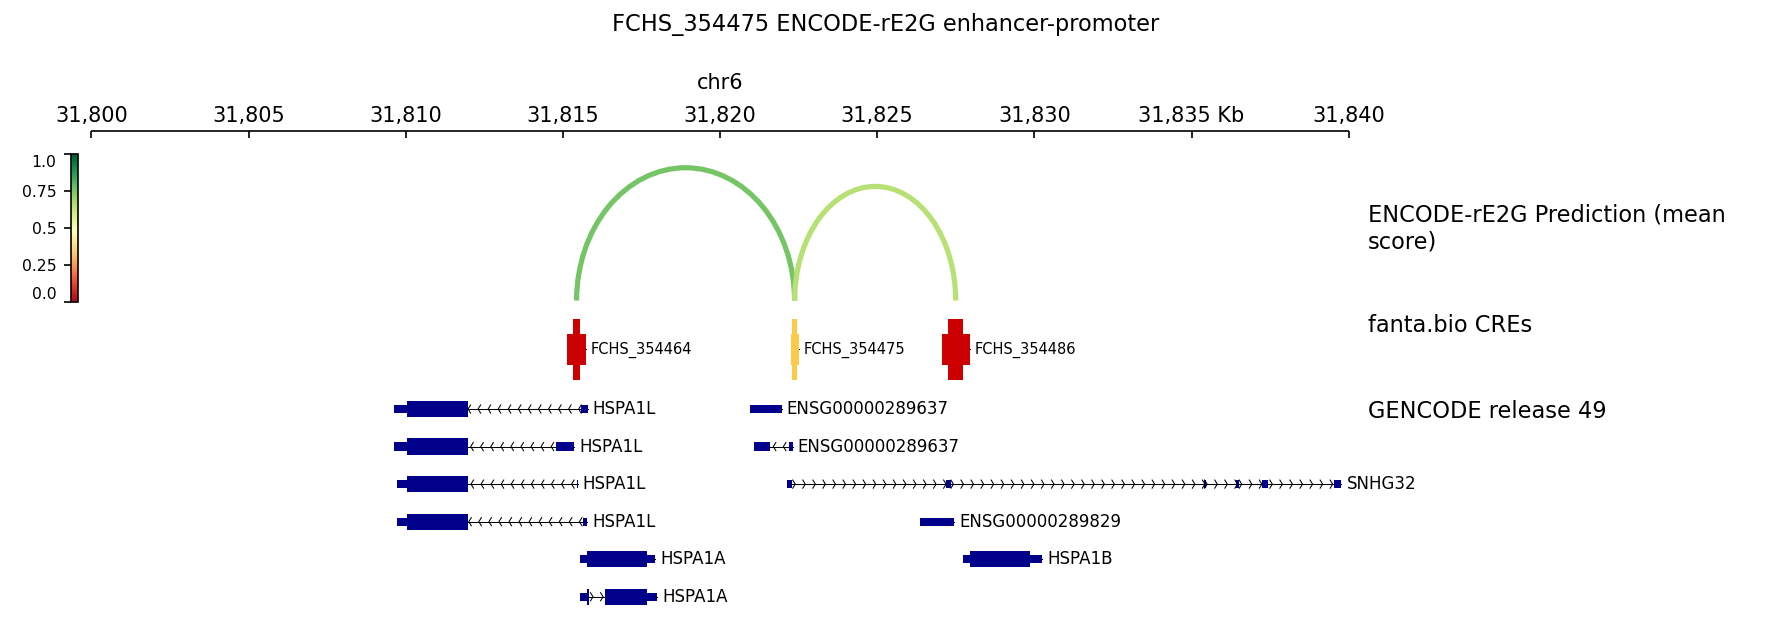

In [35]:
import subprocess
from IPython.display import Image, display

test2_ini = out_dir / "test2_tracks.ini"
test2_png = out_dir / "test2_re2g_arcs.png"
test2_ini.write_text(
    """\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = test2_re2g.links
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 2.5
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 1

[spacer]
height = 0.2

[fanta CRE]
file = test2_cre.bed9.bed
title = fanta.bio CREs
file_type = bed
height = 1.2
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[GENCODE v49]
file = test2_gencode.gtf
title = GENCODE release 49
file_type = gtf
height = 3.5
color = darkblue
prefered_name = gene_name
merge_transcripts = false
labels = true
fontsize = 8
style = UCSC
display = stacked
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test2_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test2_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G enhancer-promoter",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test2_png)))


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Test 3: hic1dmetrics Insulation Score を下に足す

- Test 2 のトラックはそのまま。その下に GSE105028 Hi-C の IS bedGraph を載せる
  - [HiC_Ctrl_merged.KR.chr6.5000.matrix.IS.bedGraph](../../out/h1d/GSE105028_hic/score_single/Ctrl_IS/HiC_Ctrl_merged.KR.chr6.5000.matrix.IS.bedGraph)
  - [HiC_HS_merged.KR.chr6.5000.matrix.IS.bedGraph](../../out/h1d/GSE105028_hic/score_single/HS_IS/HiC_HS_merged.KR.chr6.5000.matrix.IS.bedGraph)
- [bedgraph](https://pygenometracks.readthedocs.io/en/latest/content/tracks/bedgraph.html) トラック。元ファイルはスコア空欄行があるので、窓に重なるビンだけ 4 列で書き出してから読む
- Ctrl と HS の比較のため、y 軸は窓内の値で共通にする（5 kb ビンなので、この 27 kb 窓では数ステップになる）

In [36]:
# Test 3: subset hic1dmetrics IS bedGraphs to the Test 1/2 window.
# Original files have empty score fields that break bedtools tokenize.
from IPython.display import Image, display

hs_is_src = (
    repo_root
    / "out/h1d/GSE105028_hic/score_single/HS_IS"
    / "HiC_HS_merged.KR.chr6.5000.matrix.IS.bedGraph"
)
ctrl_is_src = (
    repo_root
    / "out/h1d/GSE105028_hic/score_single/Ctrl_IS"
    / "HiC_Ctrl_merged.KR.chr6.5000.matrix.IS.bedGraph"
)


def read_is_bedgraph(path):
    return pl.read_csv(
        path,
        separator="\t",
        has_header=False,
        schema={
            "chrom": pl.String,
            "start": pl.Int64,
            "end": pl.Int64,
            "score": pl.Float64,
        },
    )


def window_is(df):
    return df.filter(
        (pl.col("chrom") == REGION_CHROM)
        & (pl.col("end") > REGION_START)
        & (pl.col("start") < REGION_END)
        & pl.col("score").is_not_null()
    )


hs_win = window_is(read_is_bedgraph(hs_is_src))
ctrl_win = window_is(read_is_bedgraph(ctrl_is_src))
scores = pl.concat(
    [hs_win.select("score"), ctrl_win.select("score")]
).get_column("score")
is_min = float(scores.min())
is_max = float(scores.max())
pad = max((is_max - is_min) * 0.1, 0.005)
is_vmin = is_min - pad
is_vmax = is_max + pad

test3_hs_bg = out_dir / "test3_hs_is.bedGraph"
test3_ctrl_bg = out_dir / "test3_ctrl_is.bedGraph"
hs_win.write_csv(test3_hs_bg, separator="\t", include_header=False)
ctrl_win.write_csv(test3_ctrl_bg, separator="\t", include_header=False)

print(f"HS bins: {hs_win.height}, Ctrl bins: {ctrl_win.height}")
print(f"shared y-axis: {is_vmin:.4f} .. {is_vmax:.4f}")
display(hs_win)
display(ctrl_win)


HS bins: 8, Ctrl bins: 8
shared y-axis: 0.4643 .. 0.5425


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.53599
"""chr6""",31805000,31810000,0.498447
"""chr6""",31810000,31815000,0.503407
"""chr6""",31815000,31820000,0.505271
"""chr6""",31820000,31825000,0.50158
"""chr6""",31825000,31830000,0.507271
"""chr6""",31830000,31835000,0.505677
"""chr6""",31835000,31840000,0.470822


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.530041
"""chr6""",31805000,31810000,0.49473
"""chr6""",31810000,31815000,0.507785
"""chr6""",31815000,31820000,0.511262
"""chr6""",31820000,31825000,0.50167
"""chr6""",31825000,31830000,0.521791
"""chr6""",31830000,31835000,0.516544
"""chr6""",31835000,31840000,0.48663


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 29746.84it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 37008.56it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 11733.81it/s]
INFO:pygenometracks.tracksClass:initialize 9. [spacer]
INFO:pygenometracks.tracksClass:initialize 10. [IS HS]
100%|██████████| 8/8 [00:00<00:00, 121135.13it/s]
INFO:pygenometracks.tracksClass:initialize 11. [spacer]
INFO:pygenometracks.tracksClass:initialize 12. [IS Ctrl]
100%|██████████| 8/8 [00:00<00:00, 113743.84it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometrac

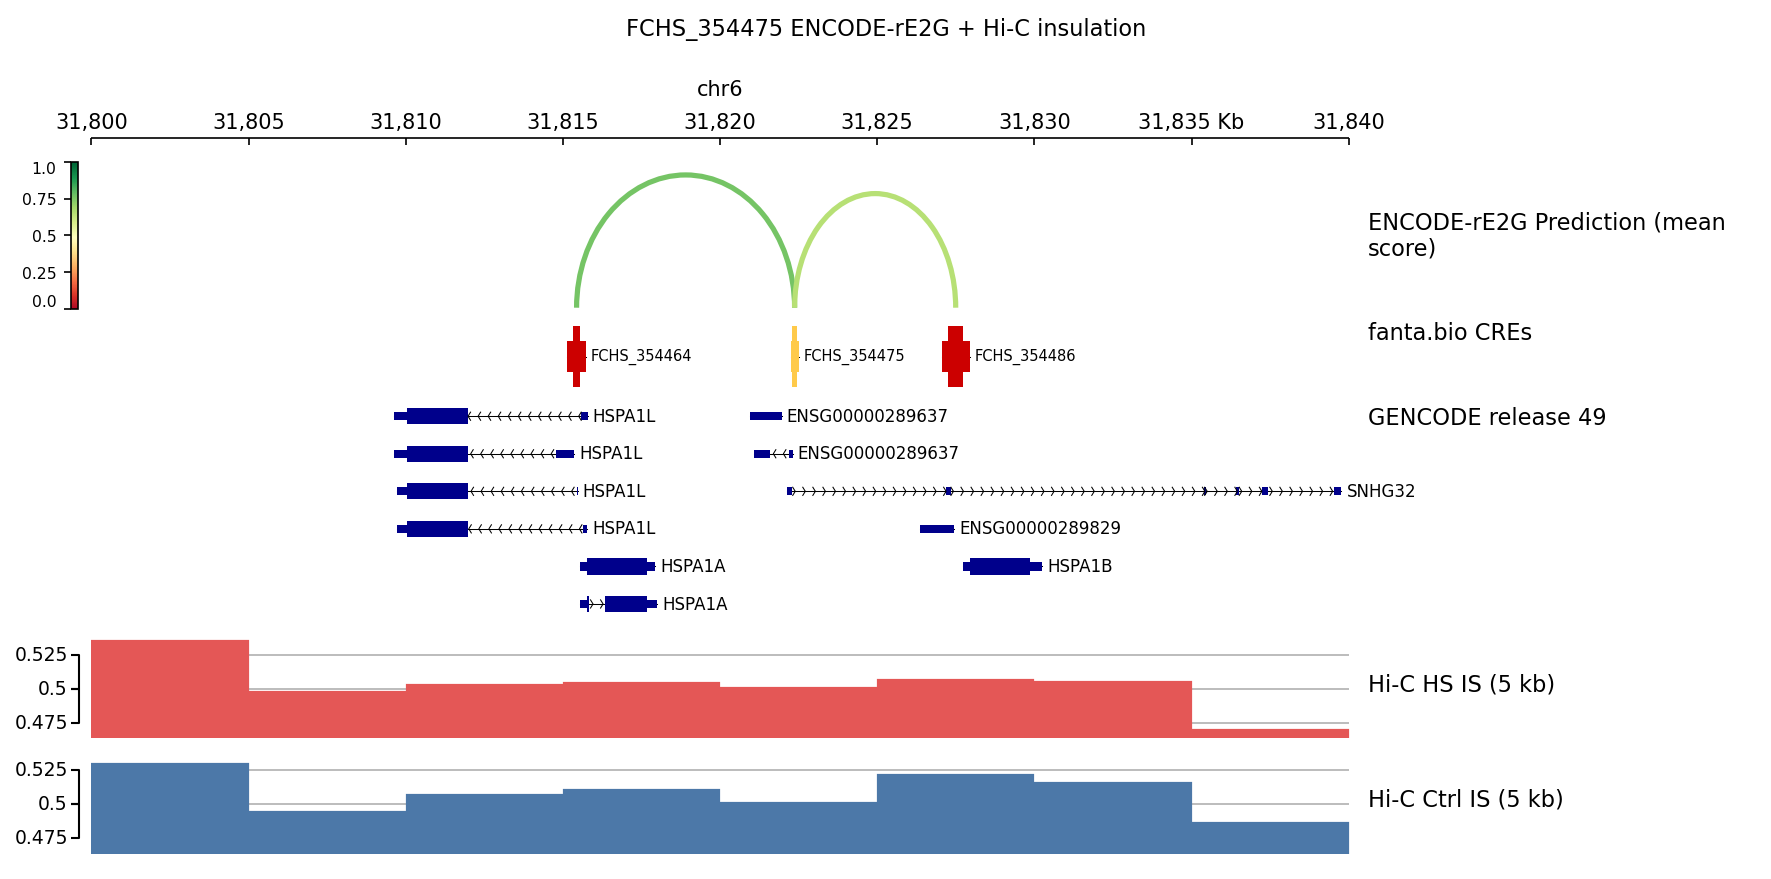

In [37]:
# Append IS tracks under the Test 2 layout. HS then Ctrl, shared y-limits.
import subprocess
from IPython.display import Image, display

test3_ini = out_dir / "test3_tracks.ini"
test3_png = out_dir / "test3_re2g_is.png"
test3_ini.write_text(
    test2_ini.read_text()
    + f"""
[spacer]
height = 0.3

[IS HS]
file = {test3_hs_bg.name}
title = Hi-C HS IS (5 kb)
file_type = bedgraph
height = 1.8
color = #E45756
type = fill
nans_to_zeros = true
min_value = {is_vmin:.4f}
max_value = {is_vmax:.4f}
show_data_range = true
grid = true

[spacer]
height = 0.15

[IS Ctrl]
file = {test3_ctrl_bg.name}
title = Hi-C Ctrl IS (5 kb)
file_type = bedgraph
height = 1.8
color = #4C78A8
type = fill
nans_to_zeros = true
min_value = {is_vmin:.4f}
max_value = {is_vmax:.4f}
show_data_range = true
grid = true
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test3_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test3_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G + Hi-C insulation",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test3_png)))


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Test 4: hic1dmetrics の ISC を下に足す

- Test 3 の下に GSE105028 Hi-C の [ISC](https://h1d.readthedocs.io/en/latest/twosample.html)（Insulation Score Change）を載せる
  - [HiC_HS_merged.KR.chr6.5000.matrix.ISC.bedGraph](../../out/h1d/GSE105028_hic/score/ISC/HiC_HS_merged.KR.chr6.5000.matrix.ISC.bedGraph)
- この計算は treat = HS、control = Ctrl。窓内では **IS_HS − IS_Ctrl** と一致する
- 正は HS で insulation が高い、負は HS で低い。色は赤（HS）と青（Ctrl）を合わせた紫。y 軸は 0 対称

In [38]:
# Test 4: subset ISC (HS minus Ctrl) to the same window as Test 3.
from IPython.display import Image, display

isc_src = (
    repo_root
    / "out/h1d/GSE105028_hic/score/ISC"
    / "HiC_HS_merged.KR.chr6.5000.matrix.ISC.bedGraph"
)
isc_win = window_is(read_is_bedgraph(isc_src))
isc_scores = isc_win.get_column("score")
isc_lim = max(abs(float(isc_scores.min())), abs(float(isc_scores.max())))
pad = max(isc_lim * 0.1, 0.002)
isc_vmax = isc_lim + pad
isc_vmin = -isc_vmax

test4_isc_bg = out_dir / "test4_isc.bedGraph"
isc_win.write_csv(test4_isc_bg, separator="\t", include_header=False)

print(f"ISC bins: {isc_win.height}")
print(f"symmetric y-axis: {isc_vmin:.4f} .. {isc_vmax:.4f}")
display(isc_win)


ISC bins: 8
symmetric y-axis: -0.0178 .. 0.0178


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.005949
"""chr6""",31805000,31810000,0.003717
"""chr6""",31810000,31815000,-0.004378
"""chr6""",31815000,31820000,-0.005991
"""chr6""",31820000,31825000,-0.00009
"""chr6""",31825000,31830000,-0.01452
"""chr6""",31830000,31835000,-0.010867
"""chr6""",31835000,31840000,-0.015808


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 28826.83it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 42224.54it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 11485.52it/s]
INFO:pygenometracks.tracksClass:initialize 9. [spacer]
INFO:pygenometracks.tracksClass:initialize 10. [IS HS]
100%|██████████| 8/8 [00:00<00:00, 97259.22it/s]
INFO:pygenometracks.tracksClass:initialize 11. [spacer]
INFO:pygenometracks.tracksClass:initialize 12. [IS Ctrl]
100%|██████████| 8/8 [00:00<00:00, 112977.89it/s]
INFO:pygenometracks.tracksClass:initialize 13. [spacer]
INFO:pygenometracks.tr

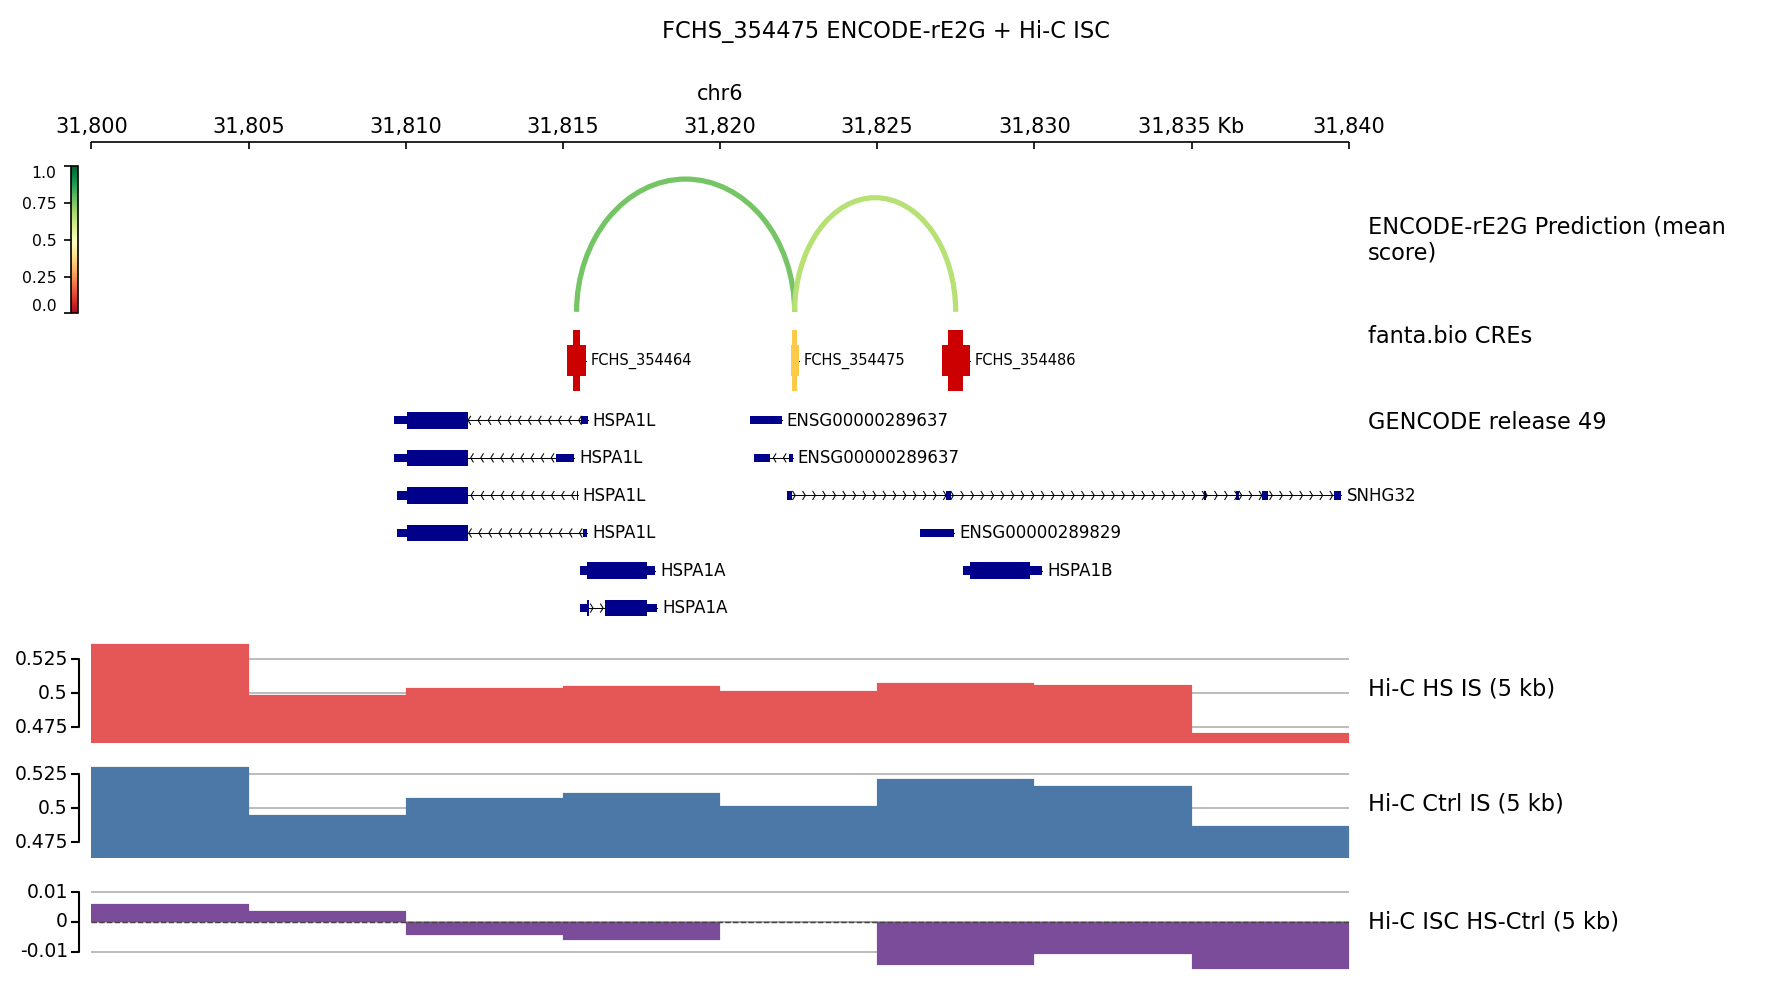

In [39]:
# Append ISC under Test 3. Red = HS > Ctrl, blue = HS < Ctrl; dashed line is zero.
import subprocess
from IPython.display import Image, display

test4_ini = out_dir / "test4_tracks.ini"
test4_png = out_dir / "test4_re2g_isc.png"
test4_ini.write_text(
    test3_ini.read_text()
    + f"""
[spacer]
height = 0.2

[ISC]
file = {test4_isc_bg.name}
title = Hi-C ISC HS-Ctrl (5 kb)
file_type = bedgraph
height = 1.8
color = #7B4C9A
negative_color = #7B4C9A
type = fill
nans_to_zeros = true
min_value = {isc_vmin:.4f}
max_value = {isc_vmax:.4f}
show_data_range = true
grid = true

[ISC zero]
file_type = hlines
y_values = 0
overlay_previous = share-y
show_data_range = false
line_width = 0.7
line_style = dashed
color = #444444
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test4_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test4_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G + Hi-C ISC",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test4_png)))


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Test 5: CTCF HiChIP の IF を下に足す

- Test 4 の下に GSE105028 CTCF HiChIP の Interaction Frequency（HS / Ctrl）を載せる
  - [CTCF_Ctrl_merged.chr6.IF.bedGraph](../../out/h1d/GSE105028_hichip/score_single/CTCF_Ctrl_IF/CTCF_Ctrl_merged.chr6.IF.bedGraph)
  - [CTCF_HS_merged.chr6.IF.bedGraph](../../out/h1d/GSE105028_hichip/score_single/CTCF_HS_IF/CTCF_HS_merged.chr6.IF.bedGraph)
- IF は Fit-Hi-C で有意なコンタクトをビンに足し、`log1p` を正の平均で割った値。0 は有意コンタクトなし
- y 軸は 0 始まりで、Ctrl と HS を共通にする

In [40]:
# Test 5: subset CTCF HiChIP Ctrl / HS Interaction Frequency to the plot window.
if_hs_src = (
    repo_root
    / "out/h1d/GSE105028_hichip/score_single/CTCF_HS_IF"
    / "CTCF_HS_merged.chr6.IF.bedGraph"
)
if_ctrl_src = (
    repo_root
    / "out/h1d/GSE105028_hichip/score_single/CTCF_Ctrl_IF"
    / "CTCF_Ctrl_merged.chr6.IF.bedGraph"
)

if_hs_win = window_is(read_is_bedgraph(if_hs_src))
if_ctrl_win = window_is(read_is_bedgraph(if_ctrl_src))
if_max = float(
    pl.concat(
        [if_hs_win.select("score"), if_ctrl_win.select("score")]
    ).get_column("score").max()
)
if_vmin = 0.0
if_vmax = max(if_max * 1.1, 0.05)

test5_hs_if_bg = out_dir / "test5_ctcf_hs_if.bedGraph"
test5_ctrl_if_bg = out_dir / "test5_ctcf_ctrl_if.bedGraph"
if_hs_win.write_csv(test5_hs_if_bg, separator="\t", include_header=False)
if_ctrl_win.write_csv(test5_ctrl_if_bg, separator="\t", include_header=False)

print(f"HS bins: {if_hs_win.height}, Ctrl bins: {if_ctrl_win.height}")
print(f"shared y-axis: {if_vmin:.4f} .. {if_vmax:.4f}")
display(if_ctrl_win)
display(if_hs_win)


HS bins: 8, Ctrl bins: 8
shared y-axis: 0.0000 .. 1.3890


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.0
"""chr6""",31805000,31810000,0.0
"""chr6""",31810000,31815000,0.79669
"""chr6""",31815000,31820000,1.262724
"""chr6""",31820000,31825000,0.79669
"""chr6""",31825000,31830000,0.0
"""chr6""",31830000,31835000,0.79669
"""chr6""",31835000,31840000,0.0


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.846563
"""chr6""",31805000,31810000,0.534122
"""chr6""",31810000,31815000,1.068244
"""chr6""",31815000,31820000,0.846563
"""chr6""",31820000,31825000,0.846563
"""chr6""",31825000,31830000,0.534122
"""chr6""",31830000,31835000,0.846563
"""chr6""",31835000,31840000,0.0


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 26886.56it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 38362.54it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 11566.14it/s]
INFO:pygenometracks.tracksClass:initialize 9. [spacer]
INFO:pygenometracks.tracksClass:initialize 10. [IS HS]
100%|██████████| 8/8 [00:00<00:00, 130561.99it/s]
INFO:pygenometracks.tracksClass:initialize 11. [spacer]
INFO:pygenometracks.tracksClass:initialize 12. [IS Ctrl]
100%|██████████| 8/8 [00:00<00:00, 148470.94it/s]
INFO:pygenometracks.tracksClass:initialize 13. [spacer]
INFO:pygenometracks.t

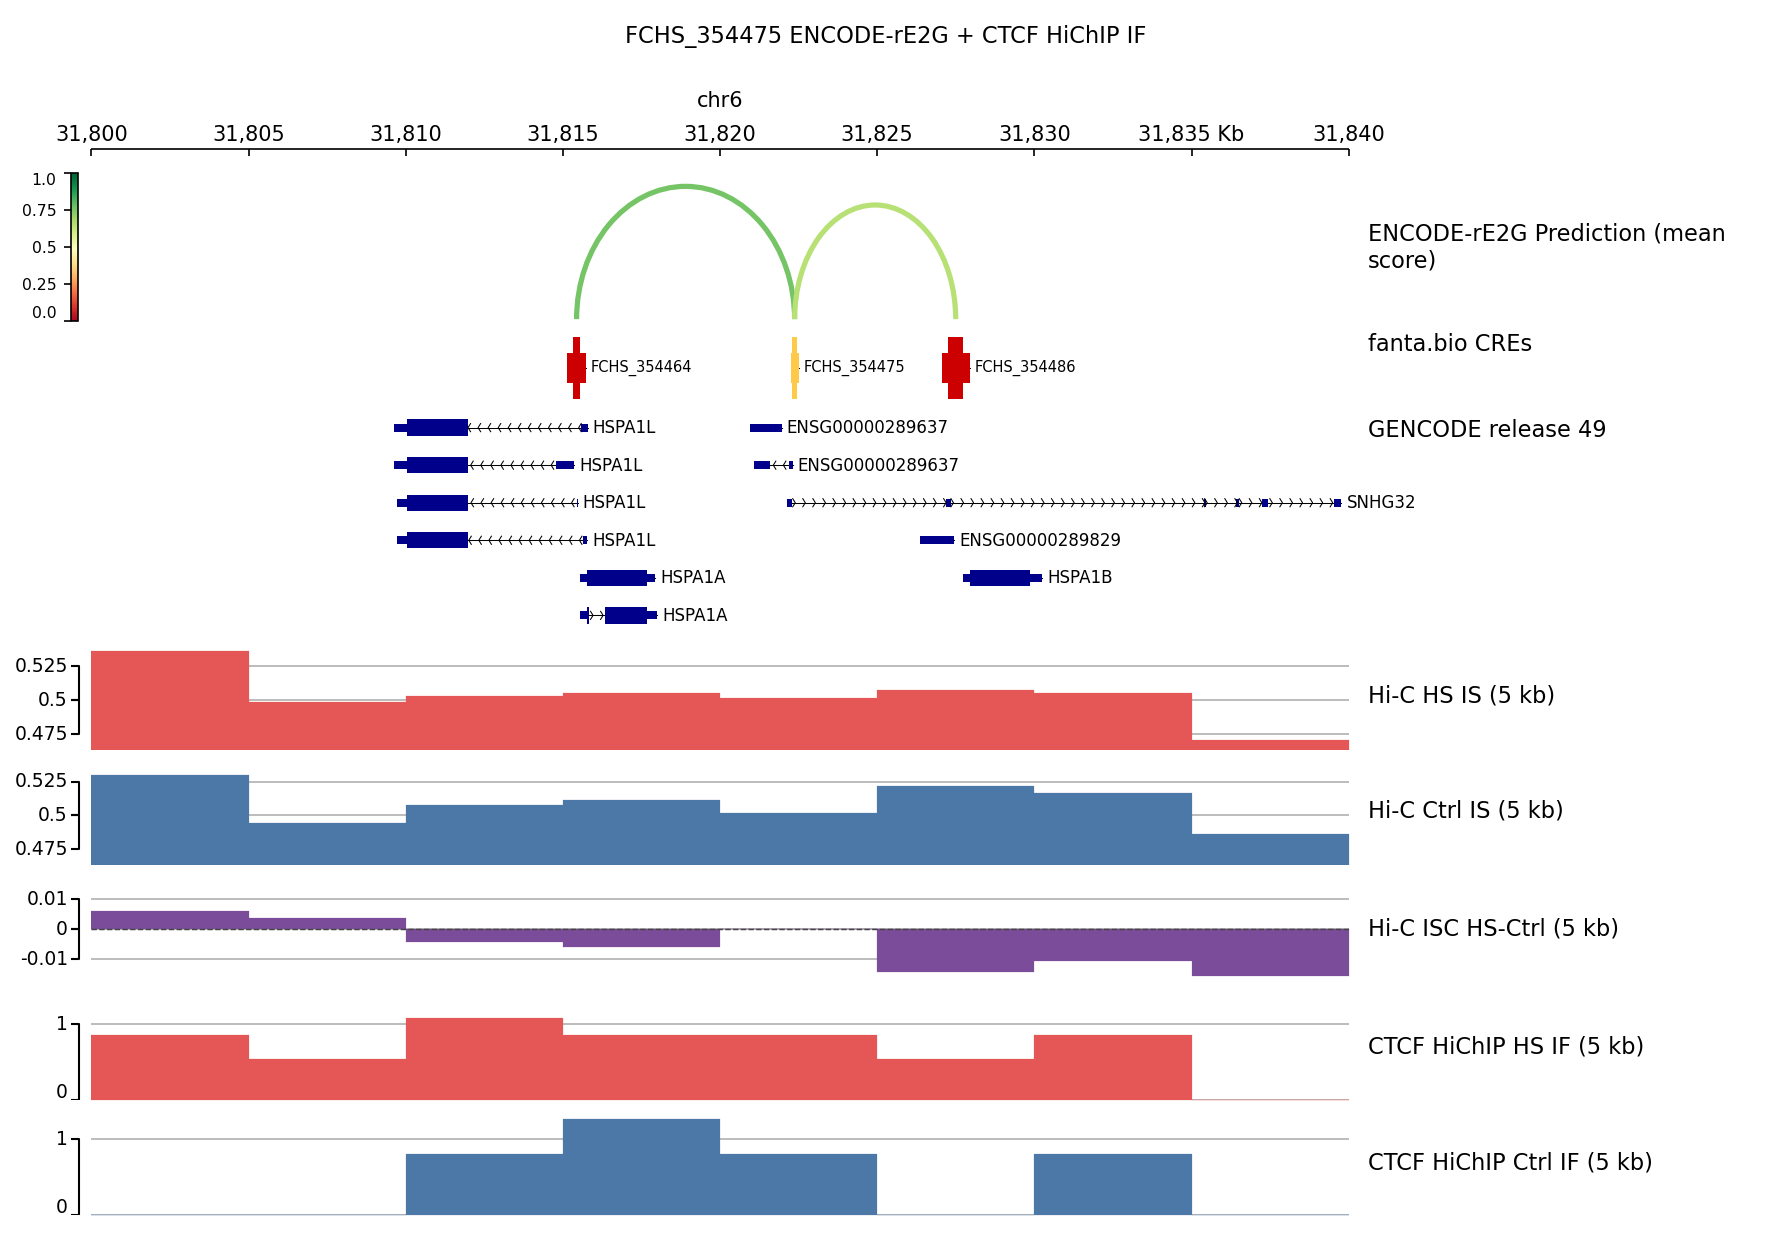

In [41]:
# Append CTCF HiChIP HS then Ctrl IF under Test 4. Shared y-axis starts at 0.
import subprocess
from IPython.display import Image, display

test5_ini = out_dir / "test5_tracks.ini"
test5_png = out_dir / "test5_re2g_if.png"
test5_ini.write_text(
    test4_ini.read_text()
    + f"""
[spacer]
height = 0.2

[CTCF HS IF]
file = {test5_hs_if_bg.name}
title = CTCF HiChIP HS IF (5 kb)
file_type = bedgraph
height = 1.8
color = #E45756
type = fill
nans_to_zeros = true
min_value = {if_vmin:.4f}
max_value = {if_vmax:.4f}
show_data_range = true
grid = true

[spacer]
height = 0.15

[CTCF Ctrl IF]
file = {test5_ctrl_if_bg.name}
title = CTCF HiChIP Ctrl IF (5 kb)
file_type = bedgraph
height = 1.8
color = #4C78A8
type = fill
nans_to_zeros = true
min_value = {if_vmin:.4f}
max_value = {if_vmax:.4f}
show_data_range = true
grid = true
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test5_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test5_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G + CTCF HiChIP IF",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test5_png)))


&nbsp;

&nbsp;

&nbsp;

## IFC Calculation

- `hic1dmetrics` でうまく計算できない + IFC は差分を引いているだけなので、緊急で自分で計算することにした
- 定義は h1d の `getIFC` と同じ。**すでに正規化済み**の IF bedGraph を `IF_HS − IF_Ctrl` する（`IFCback` は使わない。二重に `log1p` してしまう）
- 全染色体 scatter はしない。この窓で使う HS / Ctrl の IF ファイルを渡して呼ぶ

In [42]:
# IFC = already-normalized IF_treat minus IF_control (h1d getIFC).
# Pass two chromosome IF bedGraphs when a locus needs IFC; no genome-wide scatter.


def calculate_ifc(treat_if_path, control_if_path):
    treat = (
        read_is_bedgraph(treat_if_path)
        .filter(pl.col("score").is_not_null())
        .rename({"score": "if_treat"})
    )
    control = (
        read_is_bedgraph(control_if_path)
        .filter(pl.col("score").is_not_null())
        .rename({"score": "if_control"})
    )
    return (
        treat.join(
            control,
            on=["chrom", "start", "end"],
            how="inner",
            validate="1:1",
            maintain_order="left",
        )
        .select(
            "chrom",
            "start",
            "end",
            (pl.col("if_treat") - pl.col("if_control")).alias("score"),
        )
    )


ifc_hs_src = (
    repo_root
    / "out/h1d/GSE105028_hichip/score_single/CTCF_HS_IF"
    / f"CTCF_HS_merged.{REGION_CHROM}.IF.bedGraph"
)
ifc_ctrl_src = (
    repo_root
    / "out/h1d/GSE105028_hichip/score_single/CTCF_Ctrl_IF"
    / f"CTCF_Ctrl_merged.{REGION_CHROM}.IF.bedGraph"
)

ifc_chr = calculate_ifc(ifc_hs_src, ifc_ctrl_src)
ifc_win = window_is(ifc_chr)
ifc_scores = ifc_win.get_column("score")
ifc_lim = max(abs(float(ifc_scores.min())), abs(float(ifc_scores.max())))
pad = max(ifc_lim * 0.1, 0.002)
ifc_vmax = ifc_lim + pad
ifc_vmin = -ifc_vmax

test6_ifc_bg = out_dir / "test6_ctcf_ifc.bedGraph"
ifc_win.write_csv(test6_ifc_bg, separator="\t", include_header=False)

print(f"IFC bins (chr): {ifc_chr.height}, window: {ifc_win.height}")
print(f"symmetric y-axis: {ifc_vmin:.4f} .. {ifc_vmax:.4f}")
display(ifc_win)


IFC bins (chr): 34162, window: 8
symmetric y-axis: -0.9312 .. 0.9312


chrom,start,end,score
str,i64,i64,f64
"""chr6""",31800000,31805000,0.846563
"""chr6""",31805000,31810000,0.534122
"""chr6""",31810000,31815000,0.271554
"""chr6""",31815000,31820000,-0.41616
"""chr6""",31820000,31825000,0.049873
"""chr6""",31825000,31830000,0.534122
"""chr6""",31830000,31835000,0.049873
"""chr6""",31835000,31840000,0.0


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 25811.10it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 36578.23it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 11195.67it/s]
INFO:pygenometracks.tracksClass:initialize 9. [spacer]
INFO:pygenometracks.tracksClass:initialize 10. [IS HS]
100%|██████████| 8/8 [00:00<00:00, 101067.57it/s]
INFO:pygenometracks.tracksClass:initialize 11. [spacer]
INFO:pygenometracks.tracksClass:initialize 12. [IS Ctrl]
100%|██████████| 8/8 [00:00<00:00, 115704.94it/s]
INFO:pygenometracks.tracksClass:initialize 13. [spacer]
INFO:pygenometracks.t

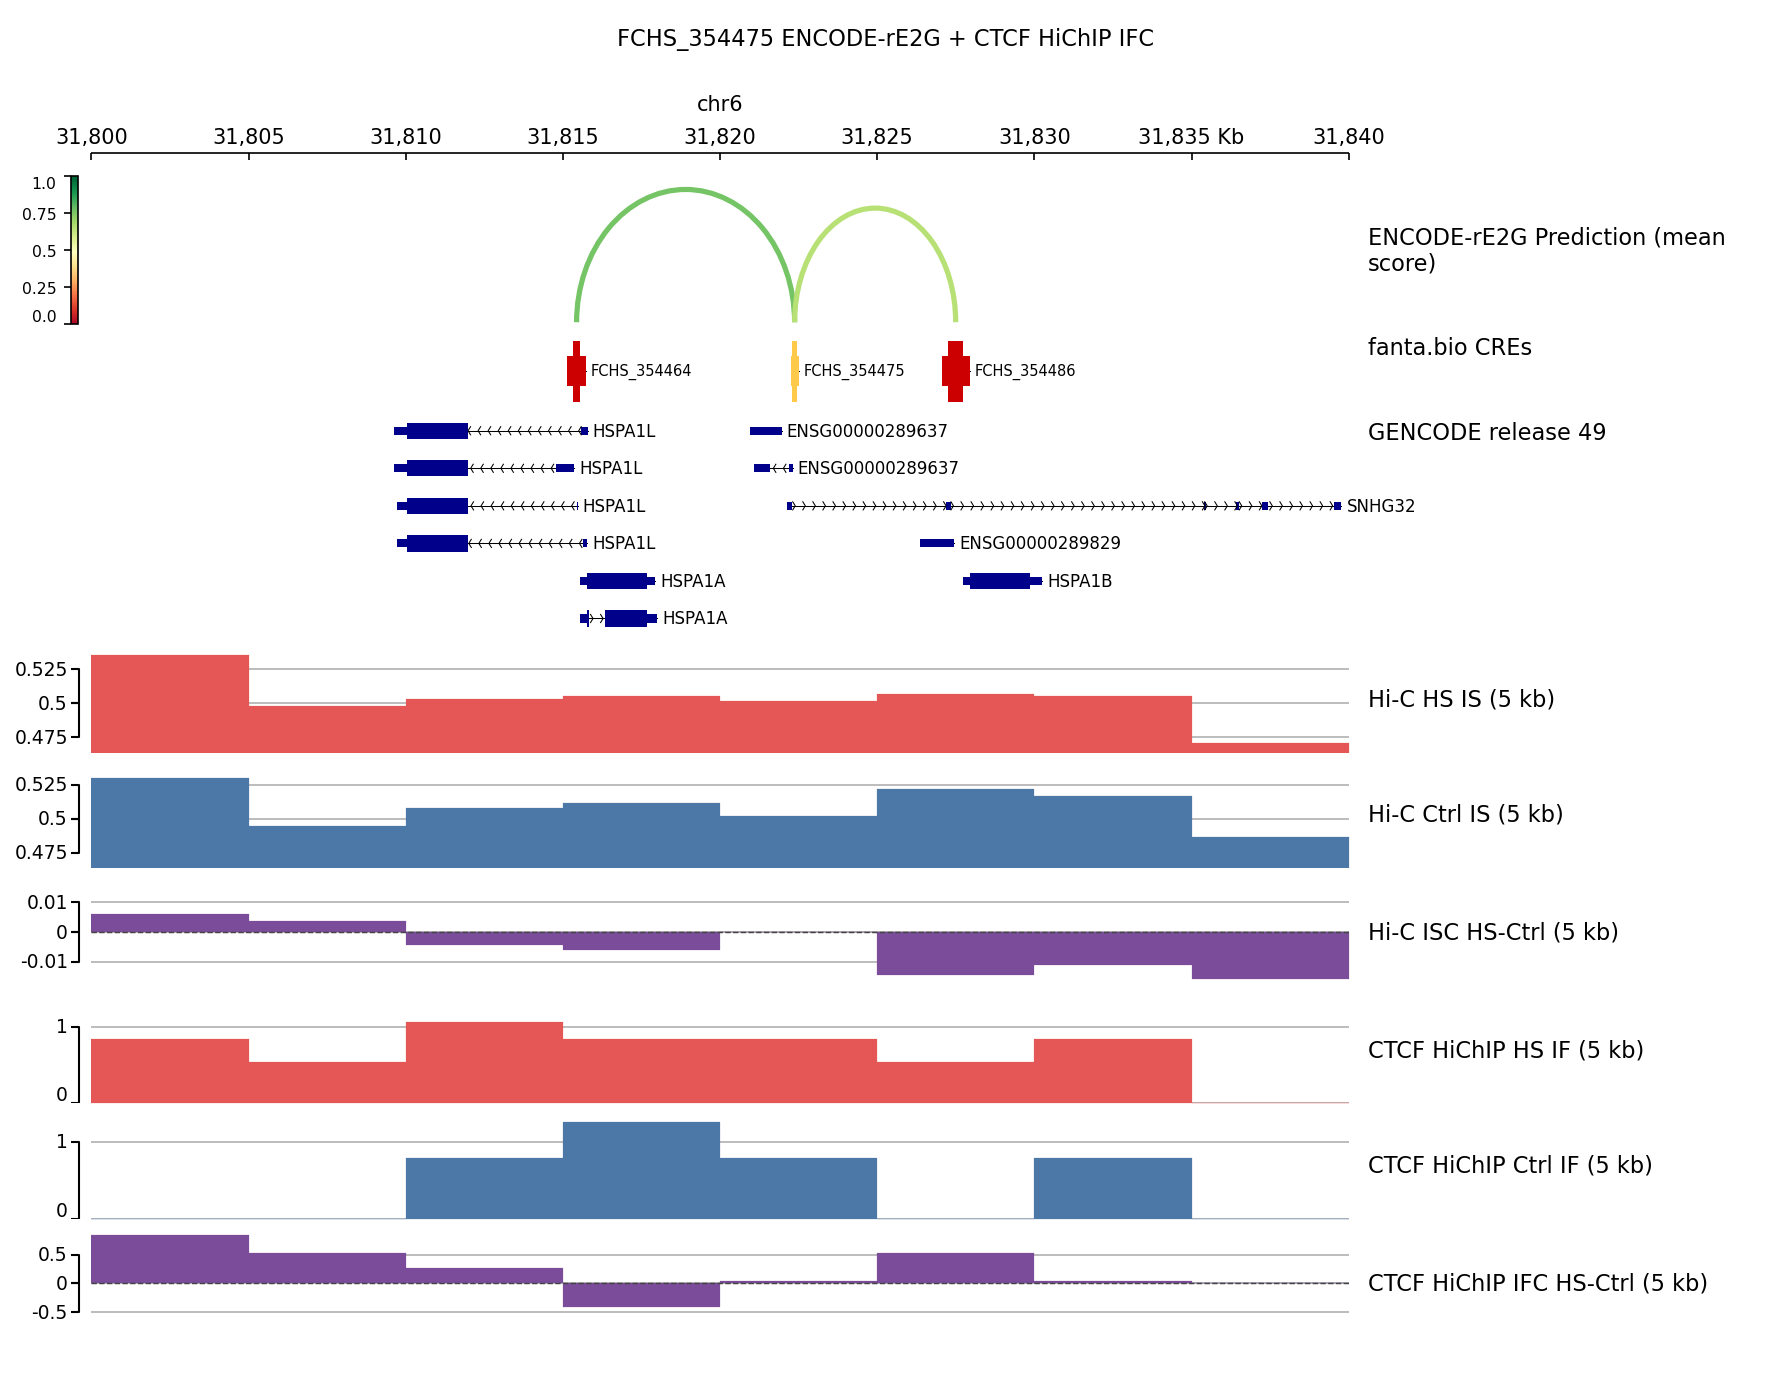

In [43]:
# Optional: append IFC under Test 5. Skip this cell if only the bedGraph is needed.
import subprocess
from IPython.display import Image, display

test6_ini = out_dir / "test6_tracks.ini"
test6_png = out_dir / "test6_re2g_ifc.png"
test6_ini.write_text(
    test5_ini.read_text()
    + f"""
[spacer]
height = 0.2

[IFC]
file = {test6_ifc_bg.name}
title = CTCF HiChIP IFC HS-Ctrl (5 kb)
file_type = bedgraph
height = 1.8
color = #7B4C9A
negative_color = #7B4C9A
type = fill
nans_to_zeros = true
min_value = {ifc_vmin:.4f}
max_value = {ifc_vmax:.4f}
show_data_range = true
grid = true

[IFC zero]
file_type = hlines
y_values = 0
overlay_previous = share-y
show_data_range = false
line_width = 0.7
line_style = dashed
color = #444444
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test6_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test6_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G + CTCF HiChIP IFC",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test6_png)))


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Test 6: GSE105028 の CTCF ChIP-seq を統合する

- ChIP-Atlas の coverage **bigWig** を IFC の下に載せる。MACS2 peak BED（q < 1×10<sup>−10</sup>）は同じディレクトリにあり、ピーク位置の確認用に残す
  - [SRX3288561](https://chip-atlas.org/view?id=SRX3288561) `SRX3288561.bw` — HS CTCF **ChIP-seq**（Ctrl は SRX3288560）
  - [SRX3288586](https://chip-atlas.org/view?id=SRX3288586) `SRX3288586.bw` — HS CTCF **ChIP-nexus**（Ctrl は SRX3288585）
- どちらも heat shock。y 軸は 0 始まりで、2 本の bigWig をこの窓の最大値で揃える


In [46]:
# Test 6: ChIP-Atlas CTCF bigWig coverage in the plot window (shared y from 0).
import os
import pyBigWig

chipatlas_dir = repo_root / "Data/Database/chipatlas/bigwig/GSE105028"
chipseq_bw = chipatlas_dir / "SRX3288561.bw"
chipnexus_bw = chipatlas_dir / "SRX3288586.bw"
chipseq_bw_rel = pathlib.Path(os.path.relpath(chipseq_bw, out_dir))
chipnexus_bw_rel = pathlib.Path(os.path.relpath(chipnexus_bw, out_dir))


def window_bw_max(path):
    bw = pyBigWig.open(str(path))
    try:
        value = bw.stats(REGION_CHROM, REGION_START, REGION_END, type="max")[0]
    finally:
        bw.close()
    return 0.0 if value is None else float(value)


chipseq_max = window_bw_max(chipseq_bw)
chipnexus_max = window_bw_max(chipnexus_bw)
chip_vmin = 0.0
chip_vmax = max(chipseq_max, chipnexus_max, 0.05) * 1.1

print(f"HS ChIP-seq window max: {chipseq_max:.4f}")
print(f"HS ChIP-nexus window max: {chipnexus_max:.4f}")
print(f"shared y-axis: {chip_vmin:.4f} .. {chip_vmax:.4f}")
print(f"bigWig paths: {chipseq_bw_rel} , {chipnexus_bw_rel}")


HS ChIP-seq window max: 0.1125
HS ChIP-nexus window max: 4.2266
shared y-axis: 0.0000 .. 4.6492
bigWig paths: ../../../../Data/Database/chipatlas/bigwig/GSE105028/SRX3288561.bw , ../../../../Data/Database/chipatlas/bigwig/GSE105028/SRX3288586.bw


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 24818.37it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 45590.26it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [GENCODE v49]
100%|██████████| 11/11 [00:00<00:00, 9723.36it/s]
INFO:pygenometracks.tracksClass:initialize 9. [spacer]
INFO:pygenometracks.tracksClass:initialize 10. [IS HS]
100%|██████████| 8/8 [00:00<00:00, 118149.41it/s]
INFO:pygenometracks.tracksClass:initialize 11. [spacer]
INFO:pygenometracks.tracksClass:initialize 12. [IS Ctrl]
100%|██████████| 8/8 [00:00<00:00, 117734.85it/s]
INFO:pygenometracks.tracksClass:initialize 13. [spacer]
INFO:pygenometracks.tr

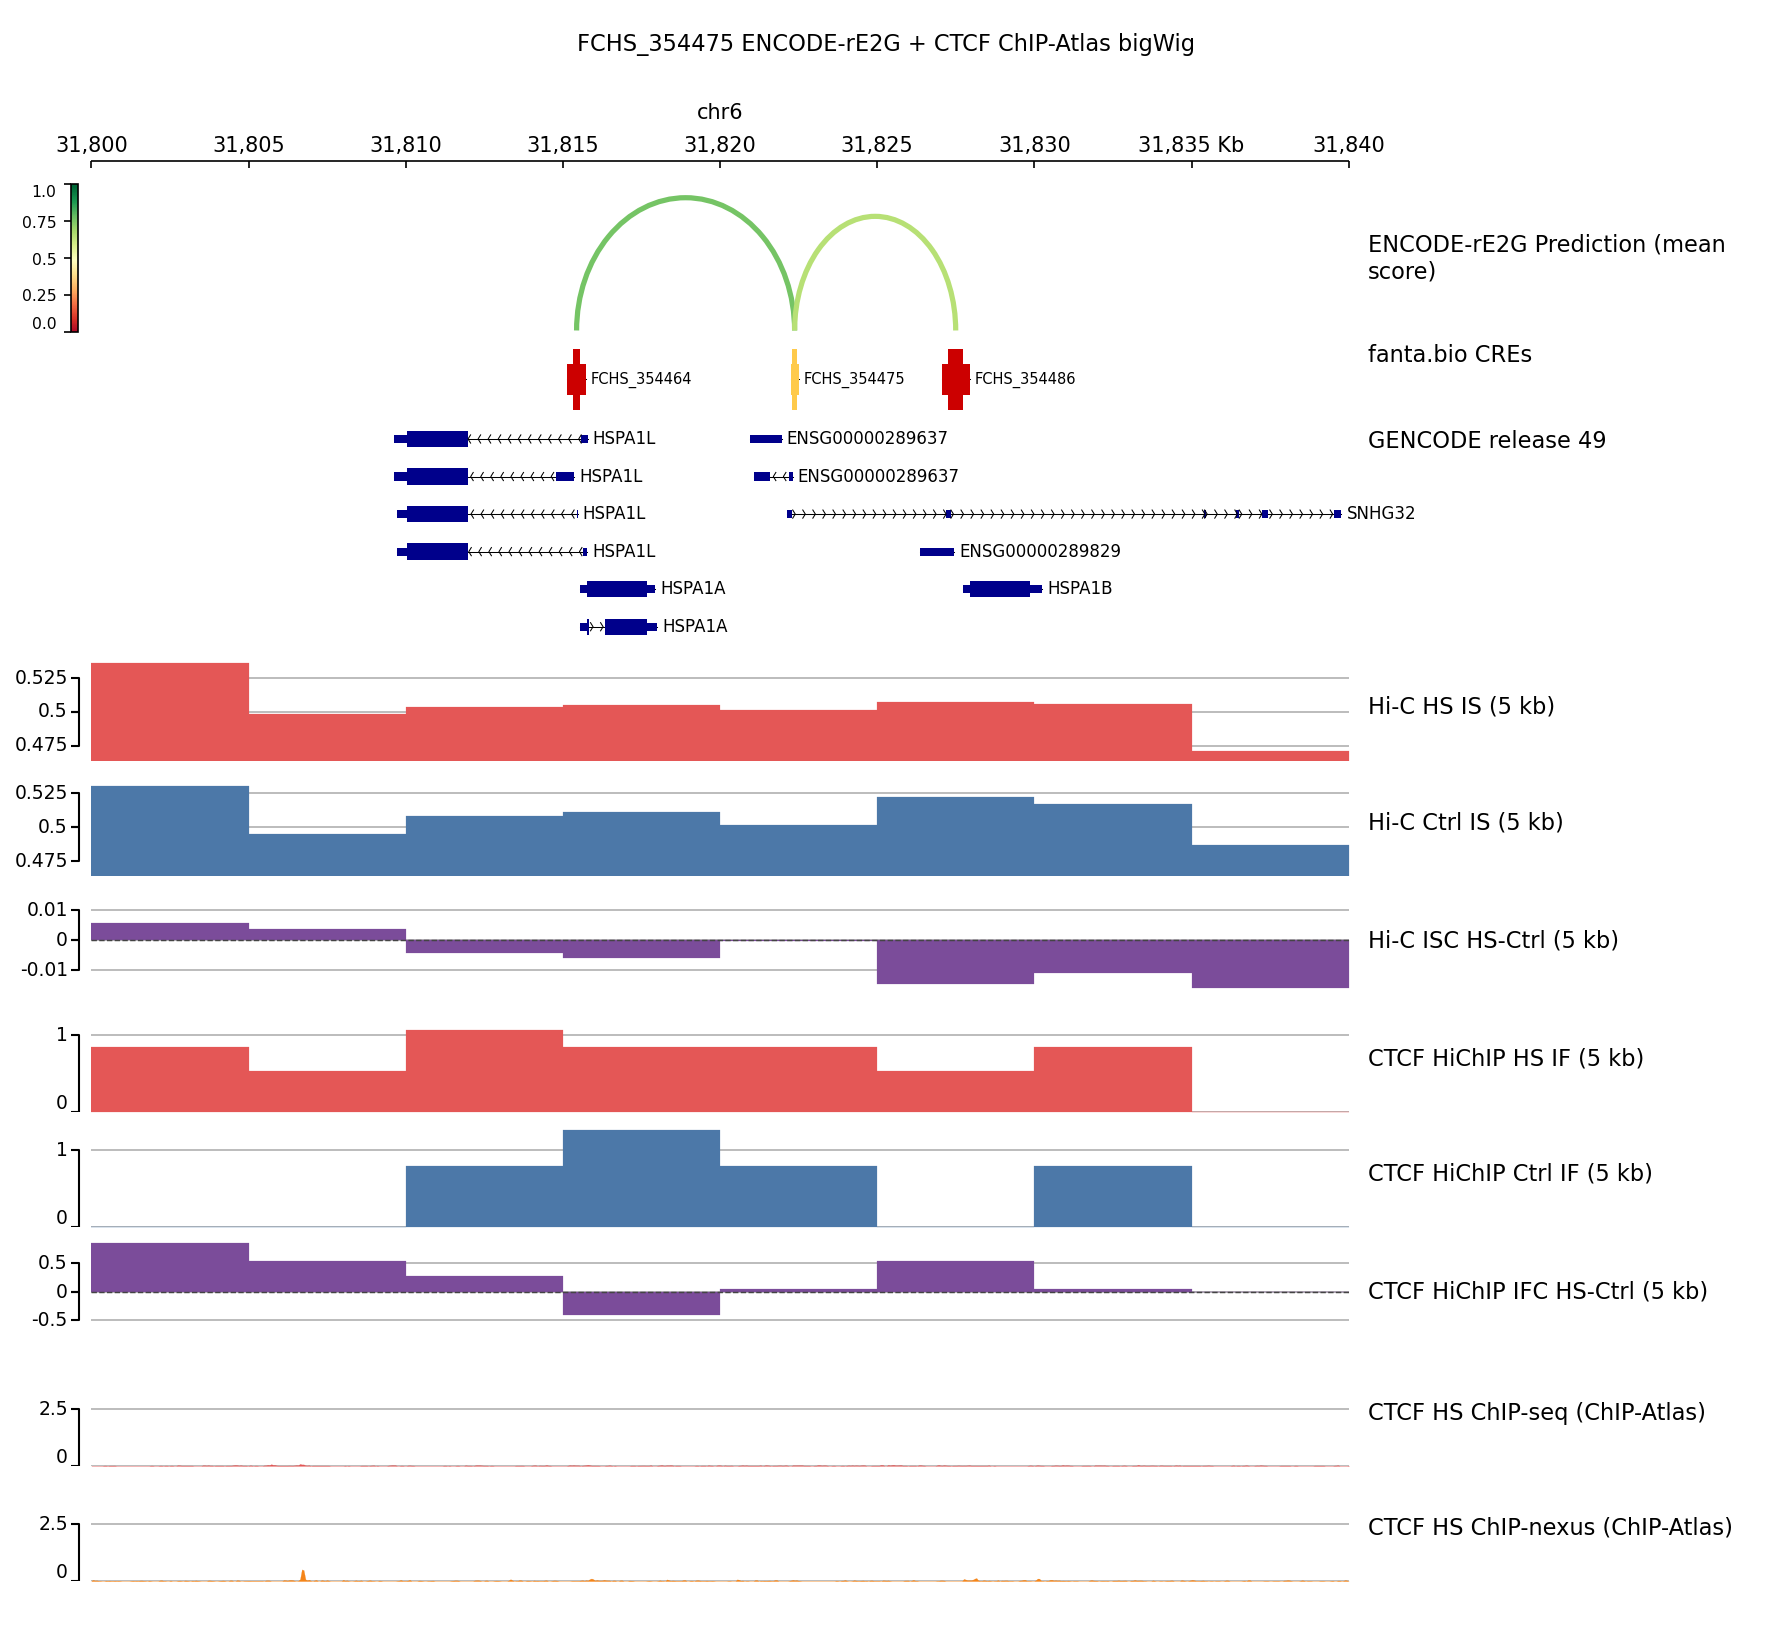

In [47]:
# Append HS CTCF ChIP-seq then ChIP-nexus bigWig under the IFC layout.
import subprocess
from IPython.display import Image, display

test6_chip_ini = out_dir / "test6_chipseq_tracks.ini"
test6_chip_png = out_dir / "test6_re2g_chipseq.png"
test6_chip_ini.write_text(
    test6_ini.read_text()
    + f"""
[spacer]
height = 0.25

[CTCF HS ChIP-seq]
file = {chipseq_bw_rel.as_posix()}
title = CTCF HS ChIP-seq (ChIP-Atlas)
file_type = bigwig
height = 1.8
color = #E45756
type = fill
nans_to_zeros = true
min_value = {chip_vmin:.4f}
max_value = {chip_vmax:.4f}
number_of_bins = 700
summary_method = mean
show_data_range = true
grid = true

[spacer]
height = 0.15

[CTCF HS ChIP-nexus]
file = {chipnexus_bw_rel.as_posix()}
title = CTCF HS ChIP-nexus (ChIP-Atlas)
file_type = bigwig
height = 1.8
color = #F58518
type = fill
nans_to_zeros = true
min_value = {chip_vmin:.4f}
max_value = {chip_vmax:.4f}
number_of_bins = 700
summary_method = mean
show_data_range = true
grid = true
"""
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(test6_chip_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.18",
        "--outFileName",
        str(test6_chip_png),
        "--title",
        "FCHS_354475 ENCODE-rE2G + CTCF ChIP-Atlas bigWig",
    ],
    check=True,
    cwd=out_dir,
)
display(Image(filename=str(test6_chip_png)))
